# Exercises week 44 — solutions

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning, October 26–30, 2026**

This notebook is a complete worked solution of the week-44 set:
cross-validating the Project 2 network with `scikit-learn`'s machinery. The
six pencil-and-paper questions of exercise 1 are answered and, where a
computation makes the answer concrete, illustrated with a few lines of
code. Exercise 2 wraps the week-41 network (`create_layers`,
`feed_forward`, `backpropagation`, `train`, `predict`, exactly as in the
lecture notebooks of weeks 41–43) as a `scikit-learn` estimator and
cross-validates it on the Runge data of Project 2 — the learning rate and
the penalty (required), the width, depth and number of epochs (optional),
the polynomial benchmark on the same folds and the test set used once.
Exercise 3 does the same for the MNIST classifier, and exercise 4 writes
the cross-validation loop by hand and shows that it reproduces
`scikit-learn`'s numbers to every digit.

Your own Project 2 code should give the same numbers if you use the same
seed (2026), the same initialisation and the same plain SGD, and numbers
in the same places if you do not: what matters is the *reasoning* around
every number — which data it was computed on, what its error bar is, and
what it is allowed to be used for. Everything is executed; the numbers
quoted in the text are the ones printed by the cells. Running the whole
notebook takes about ten minutes (the MNIST grid search of exercise 3 is
the largest part) with `mnist.npz` next to the notebook or in
`../BookPrograms/chapter10_convolutional_networks/`.

In [10]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)

BLUE, RED, YELLOW, GREY, GREEN = "#004488", "#BB5566", "#DDAA33", "#777777", "#228833"
np.set_printoptions(precision=4, suppress=True)
np.random.seed(2026)

## The network: the week-41 code, unchanged

The cell below is the dense network of the week-41 lecture notebook —
activations, `create_layers`, `feed_forward`, `predict`, `cost`,
`backpropagation` and the plain-SGD `train` of Eq. (8.70), with $L_2$ and
$L_1$ penalties and minibatches. Nothing in it knows about
cross-validation, and nothing in it is changed for this notebook: that is
the point of the wrapper of exercise 2a. (Keep the name `train` for the
function; a variable called `train` would shadow it.)

In [11]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)



ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def accuracy(X, y, layers, hidden_activation, head):
    """Fraction of correct labels; y holds integer labels for softmax, 0/1 for binary."""
    out = predict(X, layers, hidden_activation, head)
    if head == "softmax":
        return np.mean(np.argmax(out, axis=1) == y)
    return np.mean((out[:, 0] > 0.5) == (y > 0.5))


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history


def one_hot(y, n_classes=None):
    """Integer labels -> one-hot rows."""
    n_classes = int(np.max(y)) + 1 if n_classes is None else n_classes
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1.0
    return Y


The data of Project 2, part b), verbatim: $n=100$ points, $x$ uniform
on $[-1,1]$, $y=1/(1+25x^2)+\epsilon$ with $\epsilon\sim N(0,0.1^2)$, seed
2026. The noise floor of every MSE in this notebook is therefore
$\sigma^2=0.01$: no model, however good, should do better than that on
fresh data, and a model that does much better on its *training* data has
fitted noise.

In [12]:
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)
X = x.reshape(-1, 1)

cv = KFold(n_splits=5, shuffle=True, random_state=2026)     # the folds of the whole notebook
k = cv.get_n_splits()


def mse(y_true, y_pred):
    return float(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))


def se(scores):
    """Standard error of the mean of the fold scores, s / sqrt(k) with the sample standard deviation s."""
    scores = np.asarray(scores)
    return float(scores.std(ddof=1) / np.sqrt(len(scores)))


print("variance of y (the MSE of predicting the mean):", f"{y.var():.4f}", "   noise floor sigma^2 =", sigma**2)

variance of y (the MSE of predicting the mean): 0.1025    noise floor sigma^2 = 0.010000000000000002


## Exercise 1: pencil and paper — what cross-validation estimates, and what can go wrong

### a) What the $k$-fold estimate estimates

**The answer.** The $k$-fold cross-validation error estimates the expected
error, on data from the same distribution that was never seen in training,
of the *procedure* "this architecture with these hyperparameters, trained
this way on $n(k-1)/k$ points", averaged over which $n(k-1)/k$ points those
are. It is an estimate of the generalisation error of the procedure, not of
the one network you finally train, because the $k$ fold models are $k$
*different* networks (same recipe, different training sets, different
weights) that are evaluated, averaged and thrown away; the network you keep
is a new fit on all $n$ points, which cross-validation never evaluated. The
estimate is slightly pessimistic for that final network, since the fold
models had fewer points ($80$ instead of $100$ here), and it only says
anything about the final network because we assume the recipe behaves
similarly on $80$ and on $100$ points.

Exercise 2f shows the consequence: the test MSE of the final network lands
*below* the cross-validated estimate, and that is not a contradiction.

### b) The mean, the standard error, the overlap of the folds, and the choice of $k$

**The answer.** With fold errors $e_1,\dots,e_k$,

$$
\bar e=\frac1k\sum_{j=1}^k e_j,\qquad s^2=\frac{1}{k-1}\sum_{j=1}^k(e_j-\bar e)^2,\qquad
\mathrm{SE}=\frac{s}{\sqrt k},
$$

Eq. (3.93) of the notes. The $k$ numbers are not independent: training set
$j$ is all the data except fold $j$, so two training sets $j\ne j'$ share
the $k-2$ folds that are in neither, a fraction $(k-2)/(k-1)$ of their
samples — $3/4$ for $k=5$, $8/9$ for $k=10$, $(n-2)/(n-1)\to1$ for
leave-one-out. Positively correlated fold errors give the mean a *larger*
variance than independent ones would, $\mathrm{Var}(\bar e)=\frac{s^2}{k}+\frac{k-1}{k}\,\overline{\mathrm{Cov}}$,
so $s/\sqrt k$ is optimistic (too small). As $k$ grows from $2$ to $n$: the
training sets grow from $n/2$ to $n-1$ points, so the upward *bias* of the
estimate (fewer points than the final model) shrinks; but the training
sets become more and more alike, the fold errors more and more correlated,
and the *variance* of the estimate grows (and so does the cost: $n$ fits
for leave-one-out). $k=5$ or $10$ is the usual compromise (Section 2.12).

**The illustration.** The two claims about $k$ can be checked, because for
a linear model the whole exercise costs microseconds. We take a degree-5
polynomial fitted by least squares on the Runge data (a fixed procedure, no
tuning), generate $200$ independent data sets of $100$ points from the same
distribution, and for each compute the $k$-fold estimate for
$k\in\{2,5,10,25,100\}$ together with the standard error $s/\sqrt k$ it
claims. The *true* generalisation error of the procedure trained on all
$100$ points is measured once on $20\,000$ fresh points per data set. We
then compare, over the $200$ data sets: the mean of the CV estimate with
the mean true error (bias), the standard deviation of the CV estimate across
data sets (its real variability) with the average claimed standard error
(what one data set thinks its variability is), and the fraction of shared
samples between two training sets.

true generalisation error of OLS degree 5 trained on 100 points, averaged over 200 data sets: 0.02871
   k  training size  shared fraction  mean CV estimate      bias  sd across data sets  mean claimed s.e.
   2             50            0.000           0.03853   0.00981              0.05375            0.01095
   5             80            0.750           0.02965   0.00093              0.00510            0.00421
  10             90            0.889           0.02917   0.00046              0.00460            0.00413
  25             96            0.958           0.02906   0.00035              0.00441            0.00423
 100             99            0.990           0.02889   0.00018              0.00431            0.00414


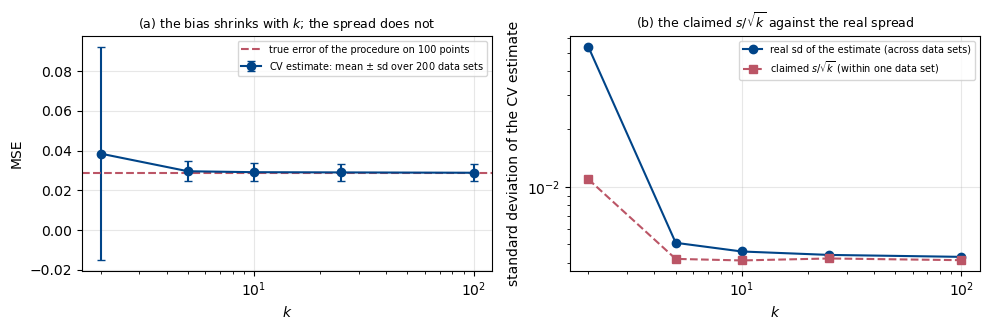

In [13]:
def fit_predict_poly(x_tr, y_tr, x_ev, degree=5):
    """Least squares on the Vandermonde matrix; returns the predictions at x_ev."""
    V = lambda z: np.vander(z, degree + 1, increasing=True)
    theta = np.linalg.pinv(V(x_tr)) @ y_tr
    return V(x_ev) @ theta


def cv_estimate(x_data, y_data, k, rng, degree=5):
    """k-fold CV of fit_predict_poly: the mean fold MSE and its claimed standard error."""
    folds = np.array_split(rng.permutation(len(y_data)), k)
    errs = []
    for val in folds:
        tr = np.setdiff1d(np.arange(len(y_data)), val)
        errs.append(mse(y_data[val], fit_predict_poly(x_data[tr], y_data[tr], x_data[val], degree)))
    errs = np.array(errs)
    return errs.mean(), errs.std(ddof=1) / np.sqrt(k)


ks = [2, 5, 10, 25, 100]
n_rep = 200
rng_rep = np.random.default_rng(2026)
x_big = np.linspace(-1, 1, 20000)
est = {kk: [] for kk in ks}; claimed = {kk: [] for kk in ks}; true_err = []
for r in range(n_rep):
    xr = rng_rep.uniform(-1, 1, n); yr = runge(xr) + rng_rep.normal(0, sigma, n)
    y_big = runge(x_big) + rng_rep.normal(0, sigma, len(x_big))
    true_err.append(mse(y_big, fit_predict_poly(xr, yr, x_big)))         # the procedure trained on all 100 points
    for kk in ks:
        m, s = cv_estimate(xr, yr, kk, rng_rep)
        est[kk].append(m); claimed[kk].append(s)
true_err = np.array(true_err)
print(f"true generalisation error of OLS degree 5 trained on 100 points, averaged over {n_rep} data sets: {true_err.mean():.5f}")
print(f"{'k':>4s} {'training size':>14s} {'shared fraction':>16s} {'mean CV estimate':>17s} {'bias':>9s} {'sd across data sets':>20s} {'mean claimed s.e.':>18s}")
for kk in ks:
    e = np.array(est[kk]); c = np.array(claimed[kk])
    print(f"{kk:4d} {n * (kk - 1) // kk:14d} {(kk - 2) / (kk - 1):16.3f} {e.mean():17.5f} {e.mean() - true_err.mean():9.5f} {e.std(ddof=1):20.5f} {c.mean():18.5f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].errorbar(ks, [np.mean(est[kk]) for kk in ks], yerr=[np.std(est[kk], ddof=1) for kk in ks], marker="o", capsize=3, color=BLUE,
               label="CV estimate: mean $\\pm$ sd over 200 data sets")
ax[0].axhline(true_err.mean(), color=RED, ls="--", label="true error of the procedure on 100 points")
ax[0].set_xscale("log"); ax[0].set_xlabel("$k$"); ax[0].set_ylabel("MSE"); ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3)
ax[0].set_title("(a) the bias shrinks with $k$; the spread does not", fontsize=9)
ax[1].plot(ks, [np.std(est[kk], ddof=1) for kk in ks], "o-", color=BLUE, label="real sd of the estimate (across data sets)")
ax[1].plot(ks, [np.mean(claimed[kk]) for kk in ks], "s--", color=RED, label="claimed $s/\\sqrt{k}$ (within one data set)")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("$k$"); ax[1].set_ylabel("standard deviation of the CV estimate")
ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3); ax[1].set_title("(b) the claimed $s/\\sqrt{k}$ against the real spread", fontsize=9)
fig.tight_layout(); plt.show()

Read the table row by row. The bias (mean CV estimate minus the true
error of the final model) is $+0.010$ for $k=2$ — fifty training points
instead of a hundred, a third more error — and shrinks towards zero as $k$
grows, as claimed; from $k=5$ on it is below $0.001$. The real standard
deviation of the estimate across data sets is large for $k=2$ (a degree-5
polynomial on fifty points occasionally extrapolates badly at the ends of
the interval) and then *hardly changes* from $k=5$ to $k=n$, $0.0051$ to
$0.0043$: the variability of a CV estimate is dominated by *which 100
points we were given*, and no choice of $k$ removes that. The claimed
standard error $s/\sqrt k$ does not fall like $1/\sqrt k$ either — it is
$0.0042$ for every $k\ge5$, because $s$, the spread of the fold errors,
grows as the folds get smaller (a fold of one point has a very noisy
error), and the two effects cancel. It sits below the real spread for every
$k$, by twenty per cent at $k=5$; the hundred fold errors of leave-one-out
share $98/99$ of their training data and are far from independent, but
what that costs is that the *real* spread stops shrinking, not that the
claimed one explodes. The lesson stands in a milder form than the
pencil answer suggests: $s/\sqrt k$ is a usable but optimistic number,
good for comparing configurations *on the same folds*, where the
correlation partly cancels, and not to be read as the uncertainty of the
number itself; and $k$ does not buy precision, only less bias, at a cost
of $k$ fits.

### c) The scaler inside the fold, and what the `Pipeline` guarantees

**The answer.** If the scaler is fitted on all $n$ points first, the mean
and the standard deviation of the held-out fold's inputs — concrete
numbers, say $\bar x_{\mathrm{fold}}$ — have entered the transformation
that the training points are trained on; the held-out fold is then no
longer data the model has never seen, and the validation error is
contaminated by it. The same holds for the mean and variance of $y$ if the
targets are scaled, and much more dramatically for anything that looks at
$y$, such as a feature selection. A `Pipeline` guarantees the right order
because `cross_validate` calls `pipeline.fit(X_train, y_train)` on the
training part of each fold, which refits *every* step (the scaler included)
on that part only, and then `pipeline.predict(X_val)`, which applies the
stored training statistics to the held-out part.

**The illustration.** For the Runge network the leak through the scaler is
small — one input, a hundred points, folds of twenty — but it is there, and
it is in the wrong direction. We run the untuned $1\to50\to1$ network of
exercise 2 both ways on the same folds: scaler fitted on all 100 points
(wrong) and on the training part of each fold (right, which is what
`make_pipeline(StandardScaler(), net)` does). (For *ordinary least squares
on polynomial features* the leak has no effect at all: rescaling $x$ by an
affine map only reparametrises the polynomial, and the predictions are
invariant — which is exactly why the point is easy to miss on Project 1
and bites on Project 2, where the fit is not invariant.)

In [14]:
class NeuralNetRegressor(BaseEstimator, RegressorMixin):
    """Exercise 2a filled in for the week-41 code (defined here because 1c already needs it).

    Rule 1: __init__ stores its keyword arguments under the same names and does
    nothing else -- BaseEstimator then supplies get_params/set_params (how
    GridSearchCV sets gamma and lmbd) and clone() gives every fold a fresh,
    untrained copy.  Rule 2: fit does all the work, stores the result in
    attributes ending in an underscore, and returns self.  Rule 3: predict
    returns a 1D array; RegressorMixin supplies score() (the R^2).
    """

    def __init__(self, hidden=(50,), activation="sigmoid", gamma=0.03, lmbd=0.0, epochs=1000, batch_size=10, seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        sizes = [X.shape[1], *self.hidden, 1]
        layers = create_layers(sizes, self.activation, np.random.default_rng(self.seed))
        self.layers_, self.history_ = train(X, y.reshape(-1, 1), layers, self.activation, "mse", gamma=self.gamma,
                                            epochs=self.epochs, batch_size=self.batch_size, lmbd2=self.lmbd,
                                            rng=np.random.default_rng(self.seed))
        return self

    def predict(self, X):
        return predict(X, self.layers_, self.activation, "mse")[:, 0]


# the leak: scaler on everything first (wrong) against scaler inside the fold (right)
X_leaky = StandardScaler().fit_transform(X)
leaky = -cross_val_score(NeuralNetRegressor(), X_leaky, y, cv=cv, scoring="neg_mean_squared_error")
clean = -cross_val_score(make_pipeline(StandardScaler(), NeuralNetRegressor()), X, y, cv=cv, scoring="neg_mean_squared_error")
for j, (tr_idx, val_idx) in enumerate(cv.split(X)):
    print(f"fold {j}: mean of x in the held-out fold {X[val_idx].mean():+.4f}, in the training part {X[tr_idx].mean():+.4f}; "
          f"validation MSE  scaler on all data {leaky[j]:.5f}   scaler inside the fold {clean[j]:.5f}")
print(f"CV MSE: scaler fitted on all 100 points {leaky.mean():.5f} +/- {se(leaky):.5f}   scaler inside the fold {clean.mean():.5f} +/- {se(clean):.5f}")

fold 0: mean of x in the held-out fold +0.0702, in the training part +0.0293; validation MSE  scaler on all data 0.03266   scaler inside the fold 0.03131
fold 1: mean of x in the held-out fold +0.2172, in the training part -0.0074; validation MSE  scaler on all data 0.03476   scaler inside the fold 0.04900
fold 2: mean of x in the held-out fold -0.0445, in the training part +0.0580; validation MSE  scaler on all data 0.01670   scaler inside the fold 0.01634
fold 3: mean of x in the held-out fold -0.0245, in the training part +0.0530; validation MSE  scaler on all data 0.03335   scaler inside the fold 0.03337
fold 4: mean of x in the held-out fold -0.0310, in the training part +0.0546; validation MSE  scaler on all data 0.03641   scaler inside the fold 0.03708
CV MSE: scaler fitted on all 100 points 0.03078 +/- 0.00358   scaler inside the fold 0.03342 +/- 0.00526


The two columns differ in every fold, because the held-out twenty points
have a different mean and spread from the training eighty, and the leaky
version has used them: in fold 1, where the held-out mean is $+0.22$
against $-0.01$ for the training part, the validation MSE moves from
$0.049$ to $0.035$. The leaky average, $0.0308$, is *lower* than the
honest $0.0334$ — the direction a leak is expected to take — and the
difference is inside the standard error, because the leak is through two
numbers of one well-behaved input. But it is a difference between a
validation error and a number that is not one, and with a scaler fitted
on $y$, with few points, or with a selection step before the model it is
not small. The `Pipeline` costs nothing; use it.

### d) "The best learning rate is 0.01, with a test MSE of 0.0094"

**The answer.** Two things are wrong. First, the learning rate was chosen
*on the test set*: the test MSE was minimised over ten candidates, so
$0.0094$ is the smallest of ten noisy numbers and no longer estimates the
error of anything — the test set has become a validation set, and there is
no test set left. Second, there is no uncertainty: ten single numbers, no
standard error, no statement of whether $0.0094$ is distinguishable from
the second-best. The honest version: "Of ten learning rates, five-fold
cross-validation on the training data selected $\gamma=0.01$ with a CV
MSE of $a\pm b$ (training MSE $c$); the next-best rates were within one
standard error. The network refitted with $\gamma=0.01$ on all training
data has a test MSE of $d$, computed once."

**The illustration.** How much does the first mistake cost? Suppose all
ten learning rates were in truth equally good, with a true MSE of exactly
$\sigma^2=0.01$ — then any honest test number should scatter around
$0.0100$. A test MSE on $100$ points with Gaussian noise has a standard
deviation of about $\sigma^2\sqrt{2/100}=0.0014$; the *minimum* of ten
such numbers sits well below $0.0100$. We simulate it.

In [15]:
rng_sim = np.random.default_rng(2026)
n_test, n_cand, n_sim = 100, 10, 20000
# ten candidates with the same true error sigma^2: their test MSEs are the mean of 100 squared noise terms
test_mses = (rng_sim.normal(0, sigma, (n_sim, n_cand, n_test)) ** 2).mean(axis=2)
print(f"one candidate, test MSE on 100 points: mean {test_mses[:, 0].mean():.5f}, sd {test_mses[:, 0].std():.5f}  (sigma^2 sqrt(2/100) = {sigma**2 * np.sqrt(2 / n_test):.5f})")
print(f"the smallest of ten: mean {test_mses.min(axis=1).mean():.5f}  -- reported as 'the test MSE of the best learning rate'")
print(f"i.e. the selection alone buys {(sigma**2 - test_mses.min(axis=1).mean()) / sigma**2 * 100:.1f} % of apparent improvement that does not exist")

one candidate, test MSE on 100 points: mean 0.01002, sd 0.00141  (sigma^2 sqrt(2/100) = 0.00141)
the smallest of ten: mean 0.00794  -- reported as 'the test MSE of the best learning rate'
i.e. the selection alone buys 20.6 % of apparent improvement that does not exist


The best of ten reports $0.0079$, on average, for a model whose true
error is $0.0100$: a twenty-per-cent improvement that does not exist, and
the colleague's $0.0094$ is well inside what selection alone produces. The
same arithmetic applies to the *best CV score of a grid* (the last row of
the self-check): the minimum over 25 grid points is biased downward in the
same way, which is why the test set is used once, afterwards, on the
single model the grid selected — exercise 2f.

### e) Early stopping: the number of epochs is a hyperparameter

**The answer.** The number of epochs changes the fitted function exactly as
$\lambda$ or the width does — a network trained for 100 epochs and the same
network trained for 3000 are different models with different test errors —
so it has to be chosen like any other hyperparameter, on data the model is
not trained on. It cannot be chosen by the training error, which with a
small enough learning rate is non-increasing in the number of epochs by
construction: it would always say "more". The procedure is early stopping:
hold out a validation fold, record its error after every epoch (or every
few), take the epoch at which it is smallest, and train the final model for
that many epochs (or keep the weights of that epoch). Averaged over the $k$
folds this is a validation curve over epochs, and exercise 2d computes it
both the expensive way (`validation_curve`, one training run per grid
value) and the cheap way (one training run per fold, the validation error
recorded after every epoch).

### f) The one-standard-error rule

**The answer.** With the CV error $\mathrm{CV}(\lambda)$ and its standard
error $\mathrm{SE}(\lambda)$ on a grid, let $\lambda_{\min}$ be the
minimiser; the rule picks

$$
\lambda_{1\mathrm{SE}}=\max\bigl\{\lambda:\ \mathrm{CV}(\lambda)\le\mathrm{CV}(\lambda_{\min})+\mathrm{SE}(\lambda_{\min})\bigr\},
$$

Eq. (3.96): the *most regularised* model whose CV error is within one
standard error of the best. The models in that set cannot be told apart by
the data — their differences are smaller than the noise of the estimate —
so the apparent advantage of the less regularised one is not believed, and
among indistinguishable models the simpler one is preferred: it has lower
variance, it is less likely to be the beneficiary of the downward bias of
part d), and (for the Lasso) it uses fewer features. When the grid is over
hidden units, "more regularised" means *fewer* units — the smallest
network within one standard error of the best; over epochs, the fewest
epochs; over depth, the fewest layers. Exercise 2b applies the rule to the
$(\gamma,\lambda)$ grid and exercise 3a to the width of the MNIST network.

## Exercise 2: the network inside scikit-learn's cross-validation — the Runge regression of Project 2

### a) The wrapper, and the check that it is the same network

The class `NeuralNetRegressor` above is exercise 2a filled in for the
week-41 code. `fit` builds the layers from the seed, trains with the week-41
`train` and stores the layers in `self.layers_`; `predict` runs the forward
pass and returns a one-dimensional array; `__init__` stores its seven
keyword arguments under their own names and nothing else. The first check
is that the wrapper is the *same network* as the training loop of week 41:
trained on all 100 points with the same settings, the two training MSEs
must agree to every digit.

In [16]:
# the week-41 loop, by hand
layers0 = create_layers([1, 50, 1], "sigmoid", np.random.default_rng(2026))
Xs = StandardScaler().fit_transform(X)
layers0, hist0 = train(Xs, y.reshape(-1, 1), layers0, "sigmoid", "mse", gamma=0.03, epochs=1000, batch_size=10, rng=np.random.default_rng(2026))
mse_loop = mse(y, predict(Xs, layers0, "sigmoid", "mse")[:, 0])
# the same through the wrapper and the pipeline
net = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,), gamma=0.03, epochs=1000))
net.fit(X, y)
mse_wrap = mse(y, net.predict(X))
print(f"training MSE on all 100 points: week-41 loop {mse_loop:.6f}   wrapper {mse_wrap:.6f}   identical: {np.isclose(mse_loop, mse_wrap)}")
print("get_params() of the estimator step:", net[-1].get_params())
print("clone() gives an untrained copy:", not hasattr(clone(net[-1]), "layers_"))

training MSE on all 100 points: week-41 loop 0.025710   wrapper 0.025710   identical: True
get_params() of the estimator step: {'activation': 'sigmoid', 'batch_size': 10, 'epochs': 1000, 'gamma': 0.03, 'hidden': (50,), 'lmbd': 0.0, 'seed': 2026}
clone() gives an untrained copy: True


**The first look.** `KFold(5, shuffle=True, random_state=2026)` fixes the
folds for the whole notebook: twenty validation points each, every point
validated exactly once. `cross_val_score` returns one score per fold, as a
*negative* MSE because `scikit-learn` maximises scores; `cross_validate`
with `return_train_score=True` adds the training MSE of each fold model
and the fitting times.

In [17]:
t0 = time.time()
scores = -cross_val_score(net, X, y, cv=cv, scoring="neg_mean_squared_error")
res = cross_validate(net, X, y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
first = {"val": scores, "train": -res["train_score"], "mean": scores.mean(), "se": se(scores)}
print(f"5-fold CV MSE {first['mean']:.4f} +/- {first['se']:.4f}   (folds {np.round(scores, 4)})")
print(f"training MSE  {first['train'].mean():.4f}            (folds {np.round(first['train'], 4)})")
print(f"one fit takes {res['fit_time'].mean():.2f} s; the ten fits of this cell took {time.time() - t0:.1f} s")

5-fold CV MSE 0.0334 +/- 0.0053   (folds [0.0313 0.049  0.0163 0.0334 0.0371])
training MSE  0.0271            (folds [0.025  0.0306 0.03   0.0255 0.0243])
one fit takes 0.35 s; the ten fits of this cell took 3.5 s


The untuned network — one hidden layer of 50 sigmoid units, $\gamma=0.03$,
$\lambda=0$, 1000 epochs of SGD with minibatches of 10 — has a
cross-validated MSE of $0.0334\pm0.0053$ and a training MSE of $0.0271$.
Two things to note before tuning anything. The fold errors range from
$0.016$ to $0.049$: a factor of three between folds of twenty points, which
is why the standard error is as large as it is and why no single
train/test split should be trusted. And both numbers are three times the
noise floor $0.01$: the network underfits, and the small gap between
training and validation error says that more capacity or more training,
not more regularisation, is the direction to look.

### b) Learning rate and penalty with `GridSearchCV` — the required part

`GridSearchCV` takes the pipeline, a grid of values addressed as
`<step name>__<parameter>` (the step name of `make_pipeline` is the class
name in lower case, `neuralnetregressor`), the `cv` object and the scoring
rule, fits every combination on every fold — $25\times5=125$ fits here —
and stores everything in `cv_results_`. With `refit=True` it then retrains
the best combination on all 100 points and exposes it as
`best_estimator_`. Two details that are easy to get wrong: the scores are
negative MSEs, and `std_test_score` is the standard deviation over the
folds *with `ddof=0`*, so the standard error $s/\sqrt k$ with the sample
standard deviation is `std_test_score / np.sqrt(k - 1)`.

In [20]:
gammas = [0.001, 0.003, 0.01, 0.03, 0.1]
lambdas = [0.0, 1e-5, 1e-4, 1e-3, 1e-2]
param_grid = {"neuralnetregressor__gamma": gammas, "neuralnetregressor__lmbd": lambdas}
t0 = time.time()
search = GridSearchCV(net, param_grid, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
search.fit(X, y)
print(f"{len(gammas) * len(lambdas) * k} fits in {time.time() - t0:.0f} s")
r = search.cv_results_
shape = (len(gammas), len(lambdas))                       # GridSearchCV orders the grid with the first parameter outermost
grid_mse = -r["mean_test_score"].reshape(shape)
grid_se = r["std_test_score"].reshape(shape) / np.sqrt(k - 1)
grid_train = -r["mean_train_score"].reshape(shape)
i_best = np.unravel_index(np.argmin(grid_mse), shape)
within = grid_mse <= grid_mse[i_best] + grid_se[i_best]
# the one-standard-error rule: among the cells within one s.e., the largest penalty, then the smallest learning rate
cands = [(i, j) for i in range(shape[0]) for j in range(shape[1]) if within[i, j]]
i_one, j_one = max(cands, key=lambda t: (lambdas[t[1]], -gammas[t[0]]))

print("CV MSE (rows gamma, columns lambda):")
print(f"{'gamma lambda':>14s}" + "".join(f"{l:>16g}" for l in lambdas))
for i, g in enumerate(gammas):
    print(f"{g:>14g}" + "".join(f"{grid_mse[i, j]:9.4f}+/-{grid_se[i, j]:.4f}" + ("*" if within[i, j] else " ") for j in range(shape[1])))
print("training MSE:")
for i, g in enumerate(gammas):
    print(f"{g:>14g}" + "".join(f"{grid_train[i, j]:16.4f}" for j in range(shape[1])))
print(f"nminimum: gamma = {gammas[i_best[0]]:g}, lambda = {lambdas[i_best[1]]:g}: CV MSE {grid_mse[i_best]:.4f} +/- {grid_se[i_best]:.4f}, training {grid_train[i_best]:.4f}")
print(f"cells within one standard error of it (*): {within.sum()}")
print(f"one-standard-error rule: gamma = {gammas[i_one]:g}, lambda = {lambdas[j_one]:g}: CV MSE {grid_mse[i_one, j_one]:.4f} +/- {grid_se[i_one, j_one]:.4f}")
print("best_params_ as scikit-learn reports them:", search.best_params_, f"  best_score_ = {search.best_score_:.5f} (negative MSE)")

125 fits in 46 s
CV MSE (rows gamma, columns lambda):
  gamma lambda               0           1e-05          0.0001           0.001            0.01
         0.001   0.1054+/-0.0112    0.1054+/-0.0112    0.1054+/-0.0112    0.1055+/-0.0112    0.1059+/-0.0111 
         0.003   0.1028+/-0.0111    0.1028+/-0.0111    0.1029+/-0.0111    0.1033+/-0.0111    0.1058+/-0.0109 
          0.01   0.0819+/-0.0110    0.0820+/-0.0110    0.0827+/-0.0110    0.0893+/-0.0114    0.1066+/-0.0106 
          0.03   0.0334+/-0.0053    0.0335+/-0.0053    0.0345+/-0.0054    0.0435+/-0.0060    0.1074+/-0.0100 
           0.1   0.0263+/-0.0041*   0.0267+/-0.0042*   0.0303+/-0.0053*   0.0540+/-0.0064    0.1114+/-0.0099 
training MSE:
         0.001          0.0996          0.0996          0.0996          0.0997          0.1003
         0.003          0.0964          0.0964          0.0965          0.0971          0.1004
          0.01          0.0738          0.0739          0.0747          0.0819          0.1018
  

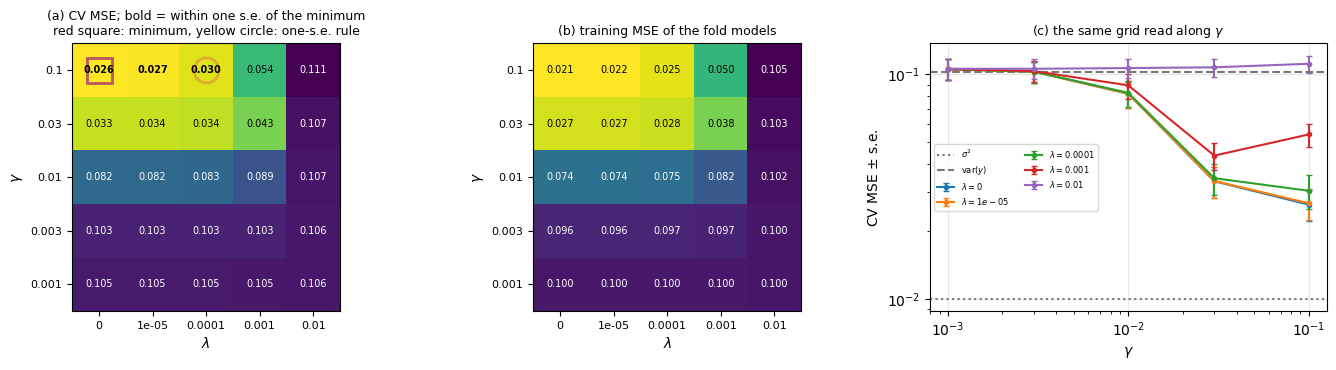

In [21]:
def heat(ax, M, title, within=None, best=None, one=None, fmt="{:.3f}"):
    im = ax.imshow(M, cmap="viridis_r", origin="lower")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([f"{v:g}" for v in lambdas], fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels([f"{v:g}" for v in gammas], fontsize=8)
    ax.set_xlabel("$\\lambda$"); ax.set_ylabel("$\\gamma$"); ax.set_title(title, fontsize=9)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=7,
                    color="white" if M[i, j] > 0.6 * M.max() else "black",
                    fontweight="bold" if within is not None and within[i, j] else "normal")
    if best is not None:
        ax.plot(best[1], best[0], "s", mfc="none", mec=RED, mew=2, ms=18)
    if one is not None:
        ax.plot(one[1], one[0], "o", mfc="none", mec=YELLOW, mew=2, ms=18)
    return im


fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
heat(ax[0], grid_mse, "(a) CV MSE; bold = within one s.e. of the minimum\nred square: minimum, yellow circle: one-s.e. rule", within, i_best, (i_one, j_one))
heat(ax[1], grid_train, "(b) training MSE of the fold models")
for j, lam in enumerate(lambdas):
    ax[2].errorbar(gammas, grid_mse[:, j], yerr=grid_se[:, j], marker="o", ms=3, capsize=2, label=f"$\\lambda={lam:g}$")
ax[2].axhline(sigma**2, color=GREY, ls=":", label="$\\sigma^2$"); ax[2].axhline(y.var(), color=GREY, ls="--", label="var($y$)")
ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_xlabel("$\\gamma$"); ax[2].set_ylabel("CV MSE $\\pm$ s.e.")
ax[2].legend(fontsize=6, ncol=2); ax[2].grid(alpha=0.3); ax[2].set_title("(c) the same grid read along $\\gamma$", fontsize=9)
fig.tight_layout(); plt.show()

**Reading the grid.** Two features dominate the heat map, and both are
about optimisation rather than about generalisation. The two smallest
learning rates, $\gamma=0.001$ and $0.003$, give a CV MSE of about $0.10$
*for every* $\lambda$ — that is the variance of $y$ (printed at the top,
$0.10$): a thousand epochs of SGD at these rates have not moved the
network away from predicting the mean, and the training MSE in panel (b)
says the same. The column $\lambda=10^{-2}$ gives $0.10$–$0.11$ for every
$\gamma$: with $n=100$ the penalty $\lambda\sum w^2$ is strong enough to
pull all the weights to zero, and again the network predicts a constant.
The remaining $3\times4$ block is where the real comparison happens, and
there the CV MSE falls monotonically with $\gamma$: the minimum is at the
largest learning rate on the grid, $\gamma=0.1$, with $\lambda=0$, at
$0.0263\pm0.0041$ — and because the minimum sits on the edge of the grid,
the honest conclusion is that $\gamma$ should be pushed further (or the
number of epochs, which plays the same role: exercise 2d).

**The one-standard-error rule.** Three cells are within one standard error
of the minimum: $\gamma=0.1$ with $\lambda\in\{0,10^{-5},10^{-4}\}$. The
rule picks the most regularised of them, $\gamma=0.1$, $\lambda=10^{-4}$,
with a CV MSE of $0.0303$: the data cannot distinguish a penalty of
$10^{-4}$ from none, and the penalised model is preferred. This is the
choice we carry to the rest of the exercise, and this table — the CV MSE
with its standard error for every cell, the training MSE beside it, the
minimum, the one-standard-error set and the chosen cell — is what Project
2's heat map of part c) should show. The penalty itself does little on this
problem, which is the right conclusion for a network that *underfits*:
regularisation is the cure for the opposite disease.

In [22]:
gamma_star, lmbd_star = gammas[i_one], lambdas[j_one]
net_star = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,), gamma=gamma_star, lmbd=lmbd_star, epochs=1000))
print(f"carried forward: gamma = {gamma_star:g}, lambda = {lmbd_star:g}")

carried forward: gamma = 0.1, lambda = 0.0001


### c) Architecture (optional): width and depth with `validation_curve` and `GridSearchCV`

`validation_curve` is `GridSearchCV` for one parameter without the refit:
it returns two arrays of shape (number of values, $k$) with the training
and the validation score of every fold, so the error bars can be computed
directly. The number of parameters of a $1\to h_1\to\dots\to1$ network is
$\sum_l (n_{l-1}+1)\,n_l$: $3h+1$ for one hidden layer of width $h$. We run
the width $h\in\{5,10,25,50,100\}$ at the $(\gamma,\lambda)$ of b), and
then the depth — the three $25$-unit networks of the exercise and, because
Project 2 asks for them, one and two hidden layers of 50 and 100 units —
through `GridSearchCV` over the tuple-valued parameter `hidden`.

width, 9 s:
  hidden  parameters             CV MSE  training MSE
       5          16     0.0248 +/- 0.0025        0.0210
      10          31     0.0288 +/- 0.0040        0.0245
      25          76     0.0300 +/- 0.0035        0.0257
      50         151     0.0303 +/- 0.0053        0.0248
     100         301     0.0280 +/- 0.0031        0.0237


/Users/mhjensen/miniforge3/envs/myenv/lib/python3.9/site-packages/sklearn/model_selection/_search.py:409: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr = np.array(param_list)



depth, 39 s:
        hidden  parameters             CV MSE  training MSE  fit time
         (25,)          76     0.0300 +/- 0.0035        0.0257     0.35s
      (25, 25)         726     0.0330 +/- 0.0042        0.0280     0.57s
  (25, 25, 25)        1376     0.1080 +/- 0.0099        0.1026     0.84s
         (50,)         151     0.0303 +/- 0.0053        0.0248     0.38s
      (50, 50)        2701     0.0208 +/- 0.0019        0.0173     0.76s
        (100,)         301     0.0280 +/- 0.0031        0.0237     0.46s
    (100, 100)       10401     0.0178 +/- 0.0019        0.0149     3.61s
best: hidden = (100, 100), CV MSE 0.0178 +/- 0.0019; within one s.e. of it: [(100, 100)]


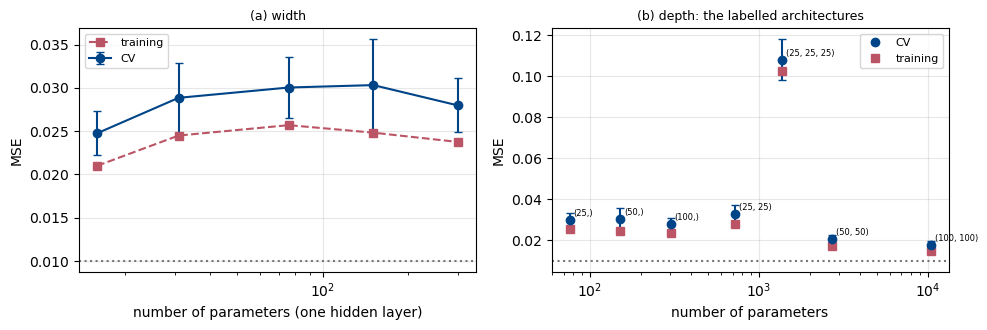

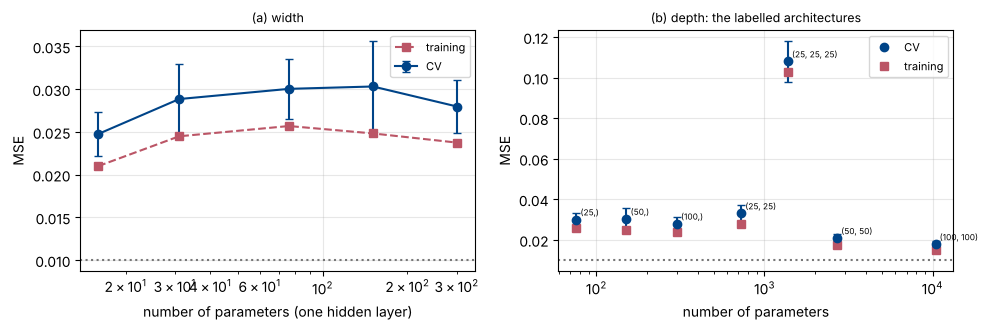

In [23]:
def n_parameters(hidden, n_in=1, n_out=1):
    sizes = [n_in, *hidden, n_out]
    return sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))


t0 = time.time()
widths = [(5,), (10,), (25,), (50,), (100,)]
tr_w, va_w = validation_curve(net_star, X, y, param_name="neuralnetregressor__hidden", param_range=widths,
                              cv=cv, scoring="neg_mean_squared_error")
tr_w, va_w = -tr_w, -va_w
print(f"width, {time.time() - t0:.0f} s:")
print(f"{'hidden':>8s} {'parameters':>11s} {'CV MSE':>18s} {'training MSE':>13s}")
for h, t, v in zip(widths, tr_w, va_w):
    print(f"{h[0]:8d} {n_parameters(h):11d} {v.mean():10.4f} +/- {se(v):.4f} {t.mean():13.4f}")

t0 = time.time()
depths = [(25,), (25, 25), (25, 25, 25), (50,), (50, 50), (100,), (100, 100)]
search_d = GridSearchCV(net_star, {"neuralnetregressor__hidden": depths}, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
search_d.fit(X, y)
rd = search_d.cv_results_
d_mse, d_se, d_train = -rd["mean_test_score"], rd["std_test_score"] / np.sqrt(k - 1), -rd["mean_train_score"]
print(f"\ndepth, {time.time() - t0:.0f} s:")
print(f"{'hidden':>14s} {'parameters':>11s} {'CV MSE':>18s} {'training MSE':>13s} {'fit time':>9s}")
for h, m, s_, t, ft in zip(depths, d_mse, d_se, d_train, rd["mean_fit_time"]):
    print(f"{str(h):>14s} {n_parameters(h):11d} {m:10.4f} +/- {s_:.4f} {t:13.4f} {ft:8.2f}s")
j_d = int(np.argmin(d_mse))
print(f"best: hidden = {depths[j_d]}, CV MSE {d_mse[j_d]:.4f} +/- {d_se[j_d]:.4f}; "
      f"within one s.e. of it: {[depths[j] for j in range(len(depths)) if d_mse[j] <= d_mse[j_d] + d_se[j_d]]}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].errorbar([n_parameters(h) for h in widths], va_w.mean(1), yerr=[se(v) for v in va_w], marker="o", capsize=3, color=BLUE, label="CV")
ax[0].plot([n_parameters(h) for h in widths], tr_w.mean(1), "s--", color=RED, label="training")
ax[0].set_xscale("log"); ax[0].set_xlabel("number of parameters (one hidden layer)"); ax[0].set_ylabel("MSE")
ax[0].axhline(sigma**2, color=GREY, ls=":"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3); ax[0].set_title("(a) width", fontsize=9)
for h, m, s_, t in zip(depths, d_mse, d_se, d_train):
    ax[1].errorbar(n_parameters(h), m, yerr=s_, marker="o", capsize=3, color=BLUE)
    ax[1].plot(n_parameters(h), t, "s", color=RED)
    ax[1].annotate(str(h), (n_parameters(h), m), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax[1].set_xscale("log"); ax[1].set_xlabel("number of parameters"); ax[1].set_ylabel("MSE"); ax[1].axhline(sigma**2, color=GREY, ls=":")
ax[1].plot([], [], "o", color=BLUE, label="CV"); ax[1].plot([], [], "s", color=RED, label="training"); ax[1].legend(fontsize=8)
ax[1].grid(alpha=0.3); ax[1].set_title("(b) depth: the labelled architectures", fontsize=9)
fig.tight_layout(); plt.show()

**Width.** Along one hidden layer the CV MSE does not resolve a trend:
the five values, $0.025$ to $0.030$, sit within about one standard error
of each other (the smallest network, five units and sixteen parameters, is
nominally the best), and the training MSE moves with them rather than
falling away from them. The classical picture of Section 2.10 — training
error falling, validation error turning up, the gap between them opening
— is the picture of *overfitting*, and this network is not there: at
$\gamma=0.1$ and 1000 epochs of SGD the width of one layer is not the
bottleneck. **Depth** is a different story, in both directions. The
architectures Project 2 asks for *are* distinguishable: two hidden layers
of 50 units give $0.0208\pm0.0019$ and two of 100 give
$0.0178\pm0.0019$, against $0.030$ and $0.028$ for one layer of the same
widths — three to four standard errors better, and the only cell within
one standard error of the best is the best itself, so the
one-standard-error rule picks $(100,100)$ as well. A second layer gives
the network a composition of sigmoids that fits the peak of the Runge
function far better than one layer of any width does with this
optimiser. In the other direction, *three* hidden layers of 25 sigmoid
units do not train at all: $0.108$, the variance of $y$, with the same
number on the training data — every additional sigmoid layer shrinks the
gradient that reaches the first one (Section 8.11, the vanishing
gradient), and plain SGD at $\gamma=0.1$ for 1000 epochs never gets the
weights moving. That failure would be invisible in a report that only
showed the two-layer result, and it is the reason the training MSE is
tabulated next to the CV MSE: a network that underfits its *training*
data has an optimisation problem, not a generalisation problem, and no
amount of cross-validation over $\lambda$ will fix it. The cost is in
the last column: the two-layer networks have twenty to seventy times the
parameters and two to three times the fitting time of the one-layer ones.
We carry the $(100,100)$ network to the benchmark of e) alongside the
one-layer choice of b).

### d) Epochs, chosen by early stopping (optional), two ways

**The expensive way** is `validation_curve` over `epochs`: every grid value
retrains the network from scratch, $6\times5=30$ runs of up to 2000
epochs. **The cheap way** uses the fact that SGD passes through every epoch
on the way to the last one: train each fold model *once* for 2000 epochs
and record the validation MSE after every epoch. With the week-41 `train`
this needs no new code — calling it 2000 times with `epochs=1` and the same
`rng` and `layers` continues exactly where it stopped, so the trajectory
is identical to one call with `epochs=2000`. The check at the end is that
the two ways agree to every digit at the six grid values.

validation_curve over the epochs: 30 training runs, 7 s
 epochs             CV MSE  training MSE   per fold
     50     0.1021 +/- 0.0115        0.0983   [0.1404 0.1091 0.0706 0.0913 0.099 ]
    100     0.0838 +/- 0.0097        0.0802   [0.1056 0.1039 0.0594 0.0865 0.0638]
    200     0.0436 +/- 0.0052        0.0360   [0.0454 0.0581 0.0253 0.0452 0.0439]
    500     0.0356 +/- 0.0064        0.0296   [0.0293 0.056  0.0167 0.0393 0.0367]
   1000     0.0303 +/- 0.0053        0.0248   [0.0246 0.0497 0.0184 0.0282 0.0307]
   2000     0.0258 +/- 0.0033        0.0214   [0.0224 0.0259 0.0158 0.0353 0.0294]
one run per fold with the error recorded after every epoch: 4 s
identical to validation_curve at the six grid values: True
minimum of the mean validation curve: epoch 1984, CV MSE 0.0221 +/- 0.0020
minimum per fold: epochs [1990, 1995, 1146, 1938, 1979], values [0.0184 0.0252 0.0145 0.0247 0.0234]
at 2000 epochs: CV MSE 0.0258, training 0.0214


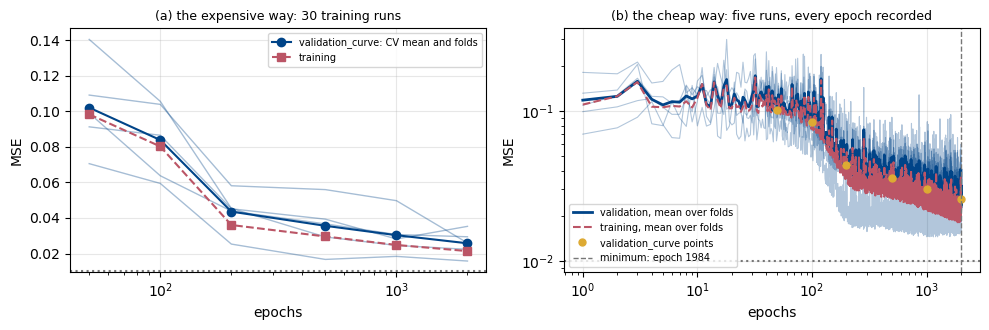

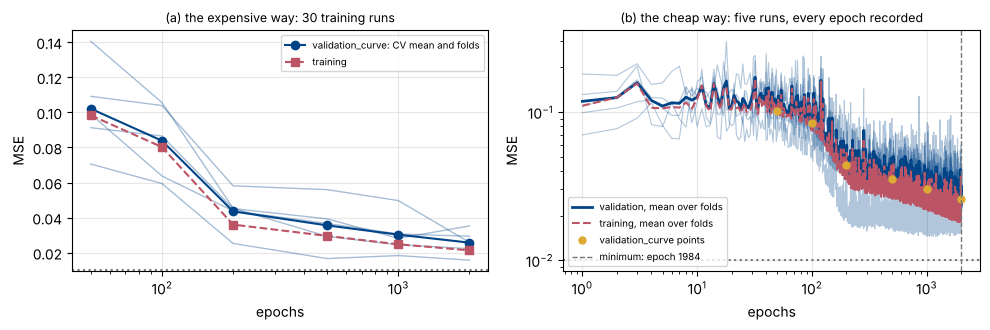

In [24]:
epoch_grid = [50, 100, 200, 500, 1000, 2000]
t0 = time.time()
tr_e, va_e = validation_curve(net_star, X, y, param_name="neuralnetregressor__epochs", param_range=epoch_grid,
                              cv=cv, scoring="neg_mean_squared_error")
tr_e, va_e = -tr_e, -va_e
print(f"validation_curve over the epochs: {len(epoch_grid) * k} training runs, {time.time() - t0:.0f} s")
print(f"{'epochs':>7s} {'CV MSE':>18s} {'training MSE':>13s}   per fold")
for e, t, v in zip(epoch_grid, tr_e, va_e):
    print(f"{e:7d} {v.mean():10.4f} +/- {se(v):.4f} {t.mean():13.4f}   {np.round(v, 4)}")

# the cheap way: one run per fold, the validation error after every epoch
t0 = time.time()
E = max(epoch_grid)
curve_val = np.zeros((k, E)); curve_tr = np.zeros((k, E))
for j, (tr_idx, val_idx) in enumerate(cv.split(X)):
    scaler = StandardScaler().fit(X[tr_idx])                                   # inside the fold
    X_tr, X_val = scaler.transform(X[tr_idx]), scaler.transform(X[val_idx])
    layers = create_layers([1, 50, 1], "sigmoid", np.random.default_rng(2026))
    rng_sgd = np.random.default_rng(2026)
    for e in range(E):
        layers, _ = train(X_tr, y[tr_idx].reshape(-1, 1), layers, "sigmoid", "mse", gamma=gamma_star, epochs=1,
                          batch_size=10, lmbd2=lmbd_star, rng=rng_sgd)
        curve_val[j, e] = mse(y[val_idx], predict(X_val, layers, "sigmoid", "mse")[:, 0])
        curve_tr[j, e] = mse(y[tr_idx], predict(X_tr, layers, "sigmoid", "mse")[:, 0])
print(f"one run per fold with the error recorded after every epoch: {time.time() - t0:.0f} s")
at_grid = curve_val[:, [e - 1 for e in epoch_grid]].T
print("identical to validation_curve at the six grid values:", np.allclose(at_grid, va_e))
mean_curve = curve_val.mean(0)
e_star = int(np.argmin(mean_curve)) + 1
e_fold = np.argmin(curve_val, axis=1) + 1
print(f"minimum of the mean validation curve: epoch {e_star}, CV MSE {mean_curve[e_star - 1]:.4f} +/- {se(curve_val[:, e_star - 1]):.4f}")
print(f"minimum per fold: epochs {e_fold.tolist()}, values {np.round(curve_val[np.arange(k), e_fold - 1], 4)}")
print(f"at 2000 epochs: CV MSE {mean_curve[-1]:.4f}, training {curve_tr.mean(0)[-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for j in range(k):
    ax[0].plot(epoch_grid, va_e[:, j], "-", color=BLUE, alpha=0.35, lw=1)
ax[0].plot(epoch_grid, va_e.mean(1), "o-", color=BLUE, label="validation_curve: CV mean and folds")
ax[0].plot(epoch_grid, tr_e.mean(1), "s--", color=RED, label="training")
ax[0].set_xscale("log"); ax[0].set_xlabel("epochs"); ax[0].set_ylabel("MSE"); ax[0].axhline(sigma**2, color=GREY, ls=":")
ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3); ax[0].set_title("(a) the expensive way: 30 training runs", fontsize=9)
ep = np.arange(1, E + 1)
for j in range(k):
    ax[1].plot(ep, curve_val[j], "-", color=BLUE, alpha=0.3, lw=0.8)
ax[1].plot(ep, mean_curve, "-", color=BLUE, lw=2, label="validation, mean over folds")
ax[1].plot(ep, curve_tr.mean(0), "--", color=RED, lw=1.5, label="training, mean over folds")
ax[1].plot(epoch_grid, va_e.mean(1), "o", color=YELLOW, ms=5, label="validation_curve points")
ax[1].axvline(e_star, color=GREY, ls="--", lw=1, label=f"minimum: epoch {e_star}")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("epochs"); ax[1].set_ylabel("MSE"); ax[1].axhline(sigma**2, color=GREY, ls=":")
ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3); ax[1].set_title("(b) the cheap way: five runs, every epoch recorded", fontsize=9)
fig.tight_layout(); plt.show()

The two ways agree exactly at the grid values, and the per-epoch curve
shows what the six points cannot: the validation MSE is still falling at
2000 epochs — from $0.030$ at 1000 to $0.026$ at 2000 — and so is the
training MSE, with a gap of four thousandths between them. The minimum of
the mean curve is at epoch 1984, in effect the end of the range, and four
of the five fold minima lie in the last seventy epochs; the fifth (fold 2,
at epoch 1146) is a shallow dip in a curve that jitters from epoch to
epoch because every epoch ends at a different minibatch. On this grid,
then, "early stopping" chooses the *largest* number of epochs offered,
which again says that the network is far from overfitting the hundred
points and that the number of epochs, like the learning rate in b), should
be pushed further. One caution about the per-epoch curve: its minimum,
$0.0221$, is the smallest of 2000 noisy numbers and is biased downward
exactly as in exercise 1d — the honest CV estimate at the chosen number
of epochs is the value at a *fixed* epoch, $0.0258\pm0.0033$ at 2000,
not the dip. This is the situation on the Runge data with plain SGD; with
a larger learning rate, momentum or Adam (Chapter 4) the curves reach the
floor in far fewer epochs and then turn upward, and the epoch of the turn
varies between folds by a factor of two or more — which is why the number
is read off the *mean* curve, and why, when training is expensive, the
per-epoch record from one run per fold is the only affordable way to get
it. If you record the validation error inside your own training loop for
Project 2, this cell is the pattern.

### e) The benchmark: OLS and Ridge on the same folds

A fair benchmark uses the *same* `cv` object — the same five splits — so
that the network and the polynomial are scored on the same twenty held-out
points in every fold and the fold-to-fold variation partly cancels in the
comparison. `make_pipeline(StandardScaler(), PolynomialFeatures(degree),
LinearRegression())` is cross-validated over the degree $1,\dots,15$, and
the Ridge version over the degree and $\lambda$; `scikit-learn`'s `alpha`
multiplies $\sum\theta^2$ without the $1/n$ in front of the data term, so
`alpha` $=n\lambda$ for the $\lambda$ of the notes.

In [ ]:
t0 = time.time()
degrees = list(range(1, 16))
poly = make_pipeline(StandardScaler(), PolynomialFeatures(), LinearRegression())
search_poly = GridSearchCV(poly, {"polynomialfeatures__degree": degrees}, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
search_poly.fit(X, y)
rp = search_poly.cv_results_
p_mse, p_se, p_train = -rp["mean_test_score"], rp["std_test_score"] / np.sqrt(k - 1), -rp["mean_train_score"]
ridge_lambdas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
ridge = make_pipeline(StandardScaler(), PolynomialFeatures(), Ridge())
search_ridge = GridSearchCV(ridge, {"polynomialfeatures__degree": degrees, "ridge__alpha": [n * l for l in ridge_lambdas]},
                            cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
search_ridge.fit(X, y)
rr = search_ridge.cv_results_
print(f"{len(degrees) * (1 + len(ridge_lambdas)) * k} polynomial fits in {time.time() - t0:.1f} s")
print(f"{'degree':>6s} {'OLS CV MSE':>20s} {'training':>9s}")
for d, m, s_, t in zip(degrees, p_mse, p_se, p_train):
    print(f"{d:6d} {m:12.4f} +/- {s_:.4f} {t:9.4f}")
j_p = int(np.argmin(p_mse))
within_p = [d for d, m in zip(degrees, p_mse) if m <= p_mse[j_p] + p_se[j_p]]
print(f"OLS: best degree {degrees[j_p]}, CV MSE {p_mse[j_p]:.4f} +/- {p_se[j_p]:.4f}; degrees within one s.e.: {within_p}; one-s.e. rule: degree {min(within_p)}")
j_r = search_ridge.best_index_
print(f"Ridge: best degree {rr['param_polynomialfeatures__degree'][j_r]}, lambda = {rr['param_ridge__alpha'][j_r] / n:g}, "
      f"CV MSE {-rr['mean_test_score'][j_r]:.4f} +/- {rr['std_test_score'][j_r] / np.sqrt(k - 1):.4f}")

# the table of the exercise: best polynomial models and the chosen networks, same folds
rows = [("OLS, degree %d" % degrees[j_p], p_mse[j_p], p_se[j_p], p_train[j_p], degrees[j_p] + 1, rp["mean_fit_time"][j_p]),
        ("Ridge, degree %d, lambda %g" % (rr['param_polynomialfeatures__degree'][j_r], rr['param_ridge__alpha'][j_r] / n),
         -rr["mean_test_score"][j_r], rr["std_test_score"][j_r] / np.sqrt(k - 1), -rr["mean_train_score"][j_r],
         rr['param_polynomialfeatures__degree'][j_r] + 1, rr["mean_fit_time"][j_r]),
        ("network 1-50-1, untuned (2a)", first["mean"], first["se"], first["train"].mean(), n_parameters((50,)), res["fit_time"].mean()),
        ("network 1-50-1, grid minimum (2b)", grid_mse[i_best], grid_se[i_best], grid_train[i_best], n_parameters((50,)), r["mean_fit_time"].reshape(shape)[i_best]),
        ("network 1-50-1, one-s.e. choice (2b)", grid_mse[i_one, j_one], grid_se[i_one, j_one], grid_train[i_one, j_one], n_parameters((50,)), r["mean_fit_time"].reshape(shape)[i_one, j_one]),
        ("network 1-50-1, 2000 epochs (2d)", mean_curve[-1], se(curve_val[:, -1]), curve_tr.mean(0)[-1], n_parameters((50,)), 2 * r["mean_fit_time"].reshape(shape)[i_one, j_one]),
        ("network %s, best architecture (2c)" % str(depths[j_d]), d_mse[j_d], d_se[j_d], d_train[j_d], n_parameters(depths[j_d]), rd["mean_fit_time"][j_d])]
print(f"\n{'model':38s} {'CV MSE +/- s.e.':>18s} {'training':>9s} {'parameters':>11s} {'fit time':>9s}")
for name, m, s_, t, p, ft in rows:
    print(f"{name:38s} {m:9.4f} +/- {s_:.4f} {t:9.4f} {p:11d} {ft:8.3f}s")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].errorbar(degrees, p_mse, yerr=p_se, marker="o", ms=4, capsize=2, color=GREEN, label="OLS, CV")
ax[0].plot(degrees, p_train, "s--", ms=4, color=RED, label="OLS, training")
ax[0].axhline(first["mean"], color=BLUE, ls="-", label="network, untuned (2a)")
ax[0].axhline(grid_mse[i_one, j_one], color=BLUE, ls="--", label="network, one-s.e. choice (2b)")
ax[0].axhline(mean_curve[-1], color=BLUE, ls=":", label="network, 2000 epochs (2d)")
ax[0].axhline(d_mse[j_d], color=YELLOW, ls="--", label=f"network {depths[j_d]} (2c)")
ax[0].set_yscale("log"); ax[0].set_xlabel("polynomial degree"); ax[0].set_ylabel("MSE"); ax[0].axhline(sigma**2, color=GREY, ls=":")
ax[0].legend(fontsize=6); ax[0].grid(alpha=0.3); ax[0].set_title("(a) the Project 1 benchmark, same folds", fontsize=9)
xx = np.linspace(-1, 1, 400).reshape(-1, 1)
ax[1].plot(x, y, ".", color=GREY, ms=4, label="training data")
ax[1].plot(xx, runge(xx), "-", color="black", lw=1, label="Runge function")
ax[1].plot(xx, search_poly.best_estimator_.predict(xx), "-", color=GREEN, label=f"OLS degree {degrees[j_p]}, refit on all points")
ax[1].plot(xx, search.best_estimator_.predict(xx), "--", color=BLUE, label="network 1-50-1, best_estimator_ of 2b")
ax[1].plot(xx, search_d.best_estimator_.predict(xx), "-.", color=YELLOW, label=f"network {depths[j_d]}, best_estimator_ of 2c")
ax[1].set_xlabel("$x$"); ax[1].set_ylabel("$y$"); ax[1].legend(fontsize=6); ax[1].grid(alpha=0.3); ax[1].set_title("(b) the two refitted models", fontsize=9)
fig.tight_layout(); plt.show()

**Does the network beat the polynomial?** The one-hidden-layer network
does not. The best polynomial — OLS of degree 11, twelve parameters, two
milliseconds per fit — has a CV MSE of $0.0211\pm0.0032$; Ridge at the
same degree with a small penalty is the same number. The network chosen in
b) has $0.0303\pm0.0053$, the grid minimum $0.0263$, and even after 2000
epochs it has not caught up ($0.0258$). The difference between the chosen
network and the polynomial is about one and a half combined standard
errors — barely resolvable, and in the polynomial's favour. The two-layer
network of c), $0.0178\pm0.0019$, gets *below* the polynomial, by about
one combined standard error, which is to say: not resolvably — at ten
thousand parameters against twelve and a thousand times the fitting time.
This is what Section 8.14 and the "What you should take away" list of
Project 2 warn about: a one-dimensional smooth function with a hundred
noisy points is a problem that linear regression on a good basis solves as
well as any network, faster and with more reliable error bars, and the
network's advantage — a basis it learns itself — only pays when the input
has many dimensions and no obvious basis, as on MNIST. Panel (b) shows the
refitted models on the data: the degree-11 polynomial and the two-layer
network follow the peak; the one-layer network has it too low and too
wide, which is where its extra MSE comes from. The polynomial pays for
its peak at the ends of the interval, where it oscillates — the Runge
phenomenon the function is named for — while both networks stay flat
there. The polynomial's own
one-standard-error set is degrees 8–11, so the rule picks degree 8 — four
degrees cannot be told apart on a hundred points — and above degree 11
the CV error explodes while the training error keeps falling: that is the
overfitting picture that the networks of c) and d) never reached.

### f) The test set, once

A fresh set of 100 points with seed 1 and the same noise. Every model that
touches it is already chosen and already refitted on the 100 training
points — `search.best_estimator_` is the grid minimum of b) refitted,
`search_d.best_estimator_` the two-layer network of c), and we also refit
the one-standard-error choice of b), its 2000-epoch version and the two
polynomials — and each is evaluated exactly once.

In [ ]:
rng_test = np.random.default_rng(1)
x_test = np.sort(rng_test.uniform(-1.0, 1.0, 100))
y_test = runge(x_test) + rng_test.normal(0.0, sigma, 100)
X_test = x_test.reshape(-1, 1)

final = {"network, grid minimum (2b)": (search.best_estimator_, grid_mse[i_best], grid_se[i_best]),
         "network, one-s.e. choice (2b)": (clone(net_star).fit(X, y), grid_mse[i_one, j_one], grid_se[i_one, j_one]),
         "network, one-s.e. choice, 2000 epochs (2d)": (clone(net_star).set_params(neuralnetregressor__epochs=2000).fit(X, y), mean_curve[-1], se(curve_val[:, -1])),
         f"network {depths[j_d]}, best architecture (2c)": (search_d.best_estimator_, d_mse[j_d], d_se[j_d]),
         f"OLS, degree {degrees[j_p]}": (search_poly.best_estimator_, p_mse[j_p], p_se[j_p]),
         "Ridge, best degree and lambda": (search_ridge.best_estimator_, -rr["mean_test_score"][j_r], rr["std_test_score"][j_r] / np.sqrt(k - 1))}
print(f"{'model':44s} {'CV MSE +/- s.e.':>18s} {'test MSE (once)':>16s} {'inside the CV error bar?':>25s}")
for name, (model, cvm, cvs) in final.items():
    t = mse(y_test, model.predict(X_test))
    print(f"{name:44s} {cvm:9.4f} +/- {cvs:.4f} {t:16.4f} {'yes' if abs(t - cvm) <= cvs else 'no':>25s}")
print(f"\nthe noise floor on 100 test points: sigma^2 = {sigma**2}, with a standard deviation of sigma^2 sqrt(2/100) = {sigma**2 * np.sqrt(2 / 100):.4f}")

**Are the test MSEs inside the CV error bars, and should they be?** All
of them come out *below* their cross-validated estimates, the one-layer
networks by two to three of their standard errors, and this is neither
luck nor a mistake — it is exercise 1a. The two-layer network of c)
reaches $0.0116$, within about one test-set standard deviation of the
noise floor $\sigma^2=0.0100$: on this test set there is essentially
nothing left to learn. The CV estimate describes the procedure trained on 80
points; the test MSE describes the single model refitted on all 100, which
is a better model, and on a smooth one-dimensional problem twenty-five per
cent more data is worth a visible amount. Two effects push the other way —
the downward bias of a selected minimum (1d), and the fact that the
standard error $s/\sqrt k$ is itself optimistic (1b) — and here they lose
to the refit. There is also a third source of scatter that none of the
error bars contain: the test set is itself a sample of 100 noisy points,
whose MSE has a standard deviation of about $0.0014$ even for a perfect
model, so two test sets with different seeds would disagree by that much.
So, no, the test MSE need not be inside the CV error bar, and when it is
not, the direction and the size of the discrepancy are what the numbers
say about the refit, the selection and the sample — not about the
correctness of the cross-validation. What *must* hold is that every
decision was taken before the test set was opened, and that it was opened
once; and it was.

## Exercise 3 (optional): the MNIST classifier of Project 2, part e)

The same wrapper with `ClassifierMixin`. `fit` stores the sorted labels in
`self.classes_` (every `scikit-learn` classifier has this attribute, and
`cross_val_predict` and `GridSearchCV` with `scoring="accuracy"` rely on
it), one-hot encodes the labels, and trains the week-41 network with the
softmax head; `predict_proba` returns the class probabilities and
`predict` the label with the largest one. The data are the official
training set, the pixels scaled to $[0,1]$; everything but the last step
uses a stratified subset of $10\,000$ images, $1000$ per digit, in random
order (the order matters for `learning_curve`, which takes the *first*
$m$ training samples of every fold). `StratifiedKFold` keeps the ten
proportions in every fold; with 1000 of each digit it gives exactly 200
per digit in every validation fold.

In [ ]:
class NeuralNetClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, hidden=(64,), activation="relu", gamma=0.1, lmbd=0.0, epochs=10, batch_size=100, seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        Y = one_hot(np.searchsorted(self.classes_, y), len(self.classes_))
        layers = create_layers([X.shape[1], *self.hidden, len(self.classes_)], self.activation, np.random.default_rng(self.seed))
        self.layers_, self.history_ = train(X, Y, layers, self.activation, "softmax", gamma=self.gamma, epochs=self.epochs,
                                            batch_size=self.batch_size, lmbd2=self.lmbd, rng=np.random.default_rng(self.seed))
        return self

    def predict_proba(self, X):
        return predict(X, self.layers_, self.activation, "softmax")

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


def confusion_matrix_multiclass(y_true, y_pred, n_classes):
    """C[i, j] = number of samples of true class i predicted as class j (week 43)."""
    Cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(Cm, (np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)), 1)
    return Cm


def per_class_from_confusion(Cm):
    """Precision and recall of every class from the K x K matrix (week 43)."""
    tp = np.diag(Cm).astype(float)
    return tp / np.maximum(Cm.sum(axis=0), 1), tp / np.maximum(Cm.sum(axis=1), 1)


for path in ("mnist.npz", os.path.join("..", "BookPrograms", "chapter10_convolutional_networks", "mnist.npz")):
    if os.path.exists(path):
        break
data = np.load(path)
x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
y_train = data["y_train"].astype(int)
x_test_m = data["x_test"].reshape(len(data["x_test"]), -1) / 255.0
y_test_m = data["y_test"].astype(int)
rng = np.random.default_rng(2026)
sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 1000, replace=False) for c in range(10)])
sub = rng.permutation(sub)                                  # random order, so that the first m of any fold are a mixture
X_sub, y_sub = x_train[sub], y_train[sub]
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
print("subset:", X_sub.shape, "class counts", np.bincount(y_sub))
print("per-digit counts in the validation folds:", [np.bincount(y_sub[val]).tolist() for _, val in cv_strat.split(X_sub, y_sub)][0], "(all five folds alike)")
# the wrapper against the week-41 loop, on the first 8000 of the subset
clf0 = NeuralNetClassifier(hidden=(64,), gamma=0.1, epochs=10).fit(X_sub[:8000], y_sub[:8000])
layers_c = create_layers([784, 64, 10], "relu", np.random.default_rng(2026))
layers_c, _ = train(X_sub[:8000], one_hot(y_sub[:8000], 10), layers_c, "relu", "softmax", gamma=0.1, epochs=10, batch_size=100, rng=np.random.default_rng(2026))
print("wrapper = week-41 loop on the last 2000:", f"{clf0.score(X_sub[8000:], y_sub[8000:]):.4f}", f"{accuracy(X_sub[8000:], y_sub[8000:], layers_c, 'relu', 'softmax'):.4f}")

wrapper = week-41 loop on the last 2000: 0.9260 0.9260


### a) Width and learning rate with `GridSearchCV`

Nine cells, five folds, ten epochs each on $8000$ images: 45 training runs.
No scaler this time — the pixels are already in $[0,1]$ and standardising
784 mostly-zero columns is not helpful — so the estimator goes into
`GridSearchCV` directly. `scoring="accuracy"` is what `ClassifierMixin`'s
`score` computes, so the scores are positive and larger is better; the
standard error is again `std_test_score / np.sqrt(k - 1)`.

In [ ]:
hiddens_c = [32, 64, 128]
gammas_c = [0.01, 0.03, 0.1]
t0 = time.time()
search_c = GridSearchCV(NeuralNetClassifier(epochs=10), {"hidden": [(h,) for h in hiddens_c], "gamma": gammas_c},
                        cv=cv_strat, scoring="accuracy", return_train_score=True)
search_c.fit(X_sub, y_sub)
print(f"{len(hiddens_c) * len(gammas_c) * k} training runs in {time.time() - t0:.0f} s")
rc = search_c.cv_results_
shape_c = (len(gammas_c), len(hiddens_c))                    # 'gamma' is first in alphabetical order, so it is the outer loop
acc_c = rc["mean_test_score"].reshape(shape_c)
se_c = rc["std_test_score"].reshape(shape_c) / np.sqrt(k - 1)
tr_c = rc["mean_train_score"].reshape(shape_c)
ib = np.unravel_index(np.argmax(acc_c), shape_c)
within_c = acc_c >= acc_c[ib] - se_c[ib]
print(f"{'gamma \\ hidden':>15s}" + "".join(f"{h:>22d}" for h in hiddens_c) + "      (CV accuracy +/- s.e., training accuracy in brackets)")
for i, g in enumerate(gammas_c):
    print(f"{g:>15g}" + "".join(f"{acc_c[i, j]:10.4f}+/-{se_c[i, j]:.4f}{'*' if within_c[i, j] else ' '}({tr_c[i, j]:.3f})" for j in range(shape_c[1])))
print(f"best: hidden {hiddens_c[ib[1]]}, gamma {gammas_c[ib[0]]:g}: {acc_c[ib]:.4f} +/- {se_c[ib]:.4f}; cells within one s.e. (*): {within_c.sum()}")
cands_c = [(i, j) for i in range(shape_c[0]) for j in range(shape_c[1]) if within_c[i, j]]
i1c, j1c = min(cands_c, key=lambda t: (hiddens_c[t[1]], -acc_c[t]))
print(f"one-standard-error rule towards the smaller network: hidden {hiddens_c[j1c]}, gamma {gammas_c[i1c]:g}: {acc_c[i1c, j1c]:.4f} +/- {se_c[i1c, j1c]:.4f}")
best_c = NeuralNetClassifier(hidden=(hiddens_c[j1c],), gamma=gammas_c[i1c], epochs=10)

**Reading the grid.** The CV accuracy rises with the learning rate and,
at the largest rate, with the width: from $0.86$ at $\gamma=0.01$ — ten
epochs at that rate are not enough SGD steps, the training accuracy says
the same — to $0.924\pm0.001$ at $\gamma=0.1$ with 128 hidden units. The
standard errors are tiny, one to three thousandths, because every
validation fold has 2000 images (compare $\sqrt{p(1-p)/2000}\approx0.006$
for one fold), and the three widths at $\gamma=0.1$ are resolved: 32, 64
and 128 units give $0.911$, $0.915$ and $0.924$, each several standard
errors from the next. So the one-standard-error set contains only the
best cell and the rule towards the smaller network changes nothing —
which is itself the answer to "which cells are indistinguishable": none
of them. The training accuracies in brackets, $0.95$ at best, show a gap
of two and a half points to the CV accuracy, and the best cell is again
on the edge of the grid in both directions, as in exercise 2b: the next
grid should go to wider networks, larger rates or more epochs.

### b) The out-of-fold confusion matrix against the test matrix

`cross_val_predict(best, X_sub, y_sub, cv=cv_strat)` trains the chosen
configuration five times and returns, for every one of the $10\,000$
images, the label predicted by the fold model that did *not* see it. The
confusion matrix of these predictions uses all the training data for
evaluation and leaves the test set untouched. For comparison we train the
same configuration once on the whole subset and build the matrix on the
official $10\,000$ test images.

In [ ]:
t0 = time.time()
y_oof = cross_val_predict(best_c, X_sub, y_sub, cv=cv_strat)
C_oof = confusion_matrix_multiclass(y_sub, y_oof, 10)
clf_sub = clone(best_c).fit(X_sub, y_sub)
C_test = confusion_matrix_multiclass(y_test_m, clf_sub.predict(x_test_m), 10)
print(f"{time.time() - t0:.0f} s")
print(f"out-of-fold accuracy on the 10 000 subset images: {np.trace(C_oof) / C_oof.sum():.4f}   (the CV mean of a): {acc_c[i1c, j1c]:.4f})")
print(f"test accuracy of the same configuration trained on the subset: {np.trace(C_test) / C_test.sum():.4f}")


def worst_pairs(Cm, n_show=6):
    off = Cm.astype(float).copy(); np.fill_diagonal(off, 0)
    order = np.argsort(off.ravel())[::-1][:n_show]
    return [(int(o // 10), int(o % 10), int(off.ravel()[o])) for o in order]


print("most frequent confusions (true -> predicted, count), out-of-fold:", worst_pairs(C_oof))
print("most frequent confusions (true -> predicted, count), test set:   ", worst_pairs(C_test))
p_oof, r_oof = per_class_from_confusion(C_oof); p_t, r_t = per_class_from_confusion(C_test)
print("per-class recall, out-of-fold:", np.round(r_oof, 3))
print("per-class recall, test set:   ", np.round(r_t, 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, Cm, title in zip(ax, (C_oof, C_test), ("(a) out-of-fold, 10 000 subset images", "(b) test set, 10 000 images")):
    off = Cm.copy(); np.fill_diagonal(off, 0)
    a.imshow(off, cmap="Reds")
    for i in range(10):
        for j in range(10):
            a.text(j, i, str(Cm[i, j]), ha="center", va="center", fontsize=6, color="white" if off[i, j] > 0.6 * off.max() else "black")
    a.set_xticks(range(10)); a.set_yticks(range(10)); a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(title + " (colour: off-diagonal)", fontsize=9)
fig.tight_layout(); plt.show()

The two matrices tell the same story: the same digit pairs dominate the
off-diagonal entries in both — $4\to9$ and $9\to4$, $3\to5$, $9\to7$
appear in both lists of the six most frequent confusions, the digits that
share strokes — and the per-class recalls agree to within one or two
points for most classes, with the threes and nines weakest in both. The
exceptions are informative: the eights are recalled at $0.89$ out of fold
and $0.95$ on the test set, and $3\to8$ and $2\to8$ lead the test list
but not the out-of-fold one. The out-of-fold matrix is built from 1000
eights, the test matrix from 974, and the fold models were trained on
8000 images against 10 000 for the test model; differences of this size
between two samples are what a per-class recall of 1000 images, with a
standard error of about one point, allows. That is what one expects when
the subset is a faithful sample of the training distribution and the test
set is drawn from the same one. **Which matrix belongs in the report?** The
out-of-fold matrix, for everything that is still being decided: it is
computed on training data, it can be looked at as often as one likes, and
it can drive decisions — more data for the weak classes, a different
architecture — without spending the test set. The test matrix is reported
*once*, at the end, for the single configuration that was finally chosen,
as part d) does; before that it is not looked at. (The one we built here,
on the subset, was for the comparison only and is not the reported one.)

### c) The learning curve

`learning_curve` trains the chosen configuration on the first $m$ samples
of each fold's training part, $m\in\{1000, 2000, 5000, 8000\}$, and
scores on the full validation fold: $4\times5=20$ training runs. The
training accuracy is computed on the same $m$ samples.

In [ ]:
t0 = time.time()
sizes_lc, tr_lc, va_lc = learning_curve(best_c, X_sub, y_sub, train_sizes=[1000, 2000, 5000, 8000], cv=cv_strat, scoring="accuracy")
print(f"{len(sizes_lc) * k} training runs in {time.time() - t0:.0f} s")
print(f"{'training size':>14s} {'CV accuracy':>20s} {'training accuracy':>18s} {'gap':>7s}")
for m, t, v in zip(sizes_lc, tr_lc, va_lc):
    print(f"{m:14d} {v.mean():12.4f} +/- {se(v):.4f} {t.mean():18.4f} {t.mean() - v.mean():7.4f}")
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.errorbar(sizes_lc, va_lc.mean(1), yerr=[se(v) for v in va_lc], marker="o", capsize=3, color=BLUE, label="CV accuracy")
ax.plot(sizes_lc, tr_lc.mean(1), "s--", color=RED, label="training accuracy")
ax.set_xscale("log"); ax.set_xlabel("training-set size"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.set_title(f"learning curve, {hiddens_c[j1c]} hidden units, $\\gamma={gammas_c[i1c]:g}$, 10 epochs", fontsize=9)
fig.tight_layout(); plt.show()

**Is the gap closing?** The CV accuracy rises steadily with the training
size, seven points from $1000$ to $8000$ images, roughly linearly in
$\log m$, and is still rising at the right end of the curve with no sign
of a plateau. The gap to the training accuracy closes from $0.054$ to
$0.026$ — but note that the training accuracy is *not* at one and rises
as well, from $0.91$ to $0.95$. Two things grow with $m$ here: the amount
of data, and the number of SGD steps, since ten epochs on $1000$ images
are only a hundred minibatch updates while ten epochs on $8000$ are eight
hundred. The network is therefore limited by data *and* by its training
budget, not by capacity: at the training accuracies we see, a wider
network at the same budget bought only a point in a), whereas every
doubling of the data buys two to three. The expectation for the full
$60\,000$ images — almost three more doublings, and seven times more SGD
steps per epoch — is a further rise of the same kind, and d) confirms it:
$0.969$ on the test set, with the week-43 result for the full set,
$0.976$ with 100 hidden units after 20 epochs, showing what the extra
epochs add. (Once the full set is used the picture changes: the gap no
longer closes by itself, and the width and the number of epochs start to
matter — the regime of exercise 2.)

### d) The full training set, and the test set once

The chosen configuration trained on all $60\,000$ images and evaluated
once on the $10\,000$ test images: the accuracy with its standard error
$\sqrt{\hat p(1-\hat p)/n}$, and the test confusion matrix.

In [ ]:
t0 = time.time()
clf_full = clone(best_c).fit(x_train, y_train)
y_hat = clf_full.predict(x_test_m)
p_hat = np.mean(y_hat == y_test_m)
C_full = confusion_matrix_multiclass(y_test_m, y_hat, 10)
print(f"trained on 60 000 images in {time.time() - t0:.0f} s")
print(f"test accuracy {p_hat:.4f} +/- {np.sqrt(p_hat * (1 - p_hat) / len(y_test_m)):.4f}   ({int((1 - p_hat) * len(y_test_m))} errors in 10 000)")
print("test confusion matrix (rows true, columns predicted):")
print(C_full)
print("most frequent confusions:", worst_pairs(C_full))
pf, rf = per_class_from_confusion(C_full)
print("per-class precision:", np.round(pf, 3)); print("per-class recall:   ", np.round(rf, 3))

This is the number for the report: one configuration, chosen on
training data, trained once on all of it, evaluated once — $0.9694$, 305
errors in $10\,000$. Its standard error of $\pm0.0017$ is the binomial one
of week 43 and says that two networks around $97\,\%$ cannot be told
apart on $10\,000$ test images unless they differ by several tenths of a
point — which is why the choice between them was made on the out-of-fold
numbers of a), with their own error bars, and not here. The matrix shows
the same pairs as the subset matrices of b) — $4\to9$ with 26, $5\to3$,
$8\to3$, $9\to4$ — with fewer errors in almost every cell.

## Exercise 4 (optional): the loop by hand, reproducing scikit-learn exactly

The exercise notebook already contains a worked version with its own fold
indices passed to `scikit-learn` as `cv=folds`. Here we go one step
further and reproduce `KFold(5, shuffle=True, random_state=2026)`
*itself*: `KFold` draws its permutation from the legacy generator
`np.random.RandomState(2026)` and cuts it into $k$ contiguous blocks (the
first $n\bmod k$ one sample larger), so the same two lines give the same
folds, and the hand-written loop — scaler fitted on the training part,
the network trained from scratch, the validation MSE recorded — must then
return the five numbers of exercise 2a, not merely their mean.

In [ ]:
def kfold_indices(n, k, seed):
    """The folds of KFold(k, shuffle=True, random_state=seed): a RandomState permutation cut into k contiguous blocks."""
    perm = np.random.RandomState(seed).permutation(n)
    sizes = np.full(k, n // k); sizes[:n % k] += 1
    bounds = np.r_[0, np.cumsum(sizes)]
    folds = []
    for i in range(k):
        val = np.sort(perm[bounds[i]:bounds[i + 1]])
        folds.append((np.setdiff1d(np.arange(n), val), val))
    return folds


def cross_validate_by_hand(make_model, X, y, folds, scale=True):
    """One validation and one training MSE per fold; the scaler is fitted on the training part of each fold only."""
    val_scores, train_scores = [], []
    for train_idx, val_idx in folds:
        X_tr, X_val = X[train_idx], X[val_idx]
        if scale:
            mean, std = X_tr.mean(axis=0), X_tr.std(axis=0)
            X_tr, X_val = (X_tr - mean) / std, (X_val - mean) / std
        model = make_model().fit(X_tr, y[train_idx])
        val_scores.append(mse(y[val_idx], model.predict(X_val)))
        train_scores.append(mse(y[train_idx], model.predict(X_tr)))
    return np.array(val_scores), np.array(train_scores)


folds = kfold_indices(n, k, 2026)
print("same folds as KFold(5, shuffle=True, random_state=2026):",
      all(np.array_equal(v, v_sk) and np.array_equal(t, t_sk) for (t, v), (t_sk, v_sk) in zip(folds, cv.split(X))))
val_h, train_h = cross_validate_by_hand(lambda: NeuralNetRegressor(hidden=(50,), gamma=0.03, epochs=1000), X, y, folds)
print(f"by hand:      CV MSE {val_h.mean():.5f} +/- {se(val_h):.5f}, training {train_h.mean():.5f}, folds {np.round(val_h, 5)}")
print(f"exercise 2a:  CV MSE {first['mean']:.5f} +/- {first['se']:.5f}, training {first['train'].mean():.5f}, folds {np.round(first['val'], 5)}")
print("identical:", np.allclose(val_h, first["val"]) and np.allclose(train_h, first["train"]))
# and the grid of 2b in miniature, with two loops instead of GridSearchCV
small = np.zeros((2, 2))
for i, g in enumerate([0.03, 0.1]):
    for j, l in enumerate([0.0, 1e-4]):
        small[i, j] = cross_validate_by_hand(lambda g=g, l=l: NeuralNetRegressor(hidden=(50,), gamma=g, lmbd=l, epochs=1000), X, y, folds)[0].mean()
print("the 2x2 corner of the grid of 2b, by hand:\n", np.round(small, 5))
print("GridSearchCV gave:\n", np.round(grid_mse[np.ix_([3, 4], [0, 2])], 5), "\nidentical:", np.allclose(small, grid_mse[np.ix_([3, 4], [0, 2])]))

by hand:      CV MSE 0.03342 +/- 0.00526, training 0.02708, folds [0.0313 0.049  0.0163 0.0334 0.0371]
exercise 2a:  CV MSE 0.03342 +/- 0.00526, training 0.02708, folds [0.0313 0.049  0.0163 0.0334 0.0371]
identical: True


the 2x2 corner of the grid of 2b, by hand:
 [[0.0334 0.0345]
 [0.0263 0.0303]]
GridSearchCV gave:
 [[0.0334 0.0345]
 [0.0263 0.0303]] 
identical: True


That is all `cross_validate` and `GridSearchCV` do: a permutation cut
into $k$ pieces, a scaler fitted $k$ times, a model trained $k$ times from
scratch, and the $k$ numbers summarised. Knowing this is what lets you read
`cv_results_` without guessing (what `std_test_score` is, why the folds
have to be fixed before the comparison, what `best_estimator_` was trained
on), and it is what you will need the day the problem does not fit the
library's assumptions — grouped samples, a time series, a model that is
trained once and evaluated at every epoch, as in exercise 2d.

## Insights, with the numbers behind them

1. **The CV error is the error of a procedure on $n(k-1)/k$ points, not
   of the model you keep.** The chosen network's test MSE lands
   *below* its CV estimate (2f), because the refit on all 100 points is a
   better model than the fold models on 80, and that is expected.
2. **Fix the folds first, compare on the same folds.** All comparisons in
   this notebook — 25 grid points, five widths, seven architectures, six
   epoch counts, fifteen degrees — use one `KFold` object, so the
   fold-to-fold variation (a factor of three between the five folds in 2a)
   partly cancels in every difference.
3. **$s/\sqrt k$ is optimistic and $k$ does not buy precision** (1b): fold
   errors sharing $3/4$ of their training data are not independent, the
   real spread of the estimate stops shrinking at $k=5$, and the claimed
   standard error sits below it. Use it to compare on the same folds, not
   to certify a number.
4. **The scaler goes inside the fold**, and the `Pipeline` puts it there
   for free (1c); for OLS on polynomial features the leak happens to be
   invisible, for the network it is not.
5. **Choosing on the test set destroys it.** The best of ten equally good
   models reports $0.0079$ for a true $0.0100$ (1d); the same bias sits on
   the best cell of any grid and on the dip of a per-epoch validation
   curve (2d), which is why the test set is opened once, afterwards.
6. **On this grid the learning rate matters, the penalty does not** (2b):
   the minimum is on the edge of the grid at $\gamma=0.1$, the two smallest
   rates and the largest penalty never leave the constant predictor, and
   the one-standard-error rule picks $\gamma=0.1$, $\lambda=10^{-4}$ over
   $\lambda=0$ because the data cannot tell them apart. The grid should be
   extended towards larger $\gamma$ — or the epochs increased (2d), which
   plays the same role.
7. **Width is not resolved, depth is** (2c): one hidden layer of 5 to 100
   units gives the same CV MSE within the error bars, two hidden layers of
   50 or 100 are better by three to four standard errors, and three sigmoid
   layers of 25 do not train at all — the training MSE next to the CV MSE
   is what shows which. The validation curve over the epochs is still
   falling at 2000 (2d): the one-layer network underfits. Early stopping is
   cheap when the validation error is recorded inside the training loop —
   one run per fold, identical to `validation_curve` to every digit.
8. **The polynomial matches the network on the Runge function** (2e): OLS
   of degree 11 with twelve parameters, $0.0211\pm0.0032$, beats the
   one-layer network's $0.0303\pm0.0053$ and is within one combined
   standard error of the two-layer network's $0.0178\pm0.0019$, at a
   thousandth of the cost. The network's advantage is not on
   one-dimensional smooth functions; on MNIST (3) it is the only one of the
   two that makes sense.
9. **The out-of-fold confusion matrix is the one to work with, the test
   matrix the one to report once** (3b, 3d), and the learning curve (3c)
   says that on a $10\,000$-image subset the classifier is limited by data
   and training budget, not by width — which is why "more hidden units" is
   the weak answer to "how do I improve it?" there, and the full training
   set ($0.969\pm0.002$ on the test set, once) is the right one.
10. **The library is thirty lines of NumPy** (4): the same permutation, the
    same folds, the same five numbers. Use the library in Project 2; know
    what it did.